# 03 · Predictive Modelling

Forecasts CPI, the Fed Funds rate, and the S&P 500 out to 2030 using
[Prophet](https://facebook.github.io/prophet/).

This notebook fixes three real issues found in the first pass of this project:

1. **Evaluation was too easy.** An 80/20 split on 70 years of data tests the model on
   predicting *14 years ahead*, which understates real forecast error. Here, accuracy is
   measured on a holdout matched to the actual forecast horizon (~5 years / 60 months).
2. **CPI's trend didn't fit recent history.** Prophet's default `changepoint_range`
   (0.8) won't place trend changepoints in the most recent 20% of training data, so the
   model couldn't adapt to the 2021-23 inflation surge — its fitted line landed ~16
   points below the actual last observation. Fixed by modeling **log(CPI)** (a price
   index grows roughly exponentially) with a wider changepoint range.
3. **Fed Funds forecast ran away in a straight line** (the original ran up to 8%+ while
   the real rate is falling). A **policy rate is mean-reverting and cyclical, not a
   growth trend** — no trend-extrapolation model is a great fit for it. This version uses
   bounded (logistic) growth and is explicit in the writeup below that this forecast
   should be trusted for the near term only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import os

PROC = "../Data/processed/"
VIS = "../visuals/"
MODELS = "../models/"
REPORTS = "../reports/"
for d in [PROC, VIS, MODELS, REPORTS]:
    os.makedirs(d, exist_ok=True)

macro = pd.read_csv(PROC + "macro_long_history.csv", parse_dates=["observation_date"])
full = pd.read_csv(PROC + "master_monthly_dataset.csv", parse_dates=["observation_date"])
print("macro:", macro.shape, "| full (with SP500):", full.shape)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


macro: (857, 4) | full (with SP500): (58, 5)


In [2]:
def _build_model(growth, yearly_seasonality):
    # changepoint_range=0.95 (default 0.8) + a higher changepoint_prior_scale lets
    # the trend actually adapt to recent regime shifts (e.g. 2021-23 inflation
    # surge / hiking cycle) instead of freezing the trend before the data ends.
    return Prophet(growth=growth, yearly_seasonality=yearly_seasonality,
                    weekly_seasonality=False, daily_seasonality=False,
                    changepoint_range=0.95, changepoint_prior_scale=0.15)

def evaluate_holdout(data, growth="linear", cap=None, floor=None, yearly_seasonality=False,
                      test_months=60, log_transform=False):
    """Holdout on the LAST `test_months` months -- matched to our 5yr forecast horizon,
    rather than an arbitrary 80/20 split that (for a 70yr series) would test on a
    14-year-ahead extrapolation and understate real near-term error."""
    test_months = min(test_months, max(6, len(data) // 4))
    split = len(data) - test_months
    train, test = data.iloc[:split].copy(), data.iloc[split:].copy()
    if log_transform:
        train["y"] = np.log(train["y"])
    if growth == "logistic":
        train["cap"] = np.log(cap) if log_transform else cap
        train["floor"] = floor
    m = _build_model(growth, yearly_seasonality)
    m.fit(train)
    future = test[["ds"]].copy()
    if growth == "logistic":
        future["cap"] = np.log(cap) if log_transform else cap
        future["floor"] = floor
    fc = m.predict(future)
    yhat = np.exp(fc["yhat"]) if log_transform else fc["yhat"]
    mae = mean_absolute_error(test["y"], yhat)
    rmse = np.sqrt(mean_squared_error(test["y"], yhat))
    return mae, rmse

def fit_final(data, periods, growth="linear", cap=None, floor=None, yearly_seasonality=False,
              log_transform=False):
    """Refit on ALL available data for the actual forward forecast, then apply a
    boundary bias-correction: Prophet's trend can still under/overfit right at the
    edge of training data even with a widened changepoint_range, which shows up as
    a visible jump between the last real observation and the first forecast point.
    We measure that gap at the last historical date (using only training data --
    no leakage) and shift the whole future forecast by it, so it continues smoothly
    from where the actual data ends."""
    d = data.copy()
    if log_transform:
        d["y"] = np.log(d["y"])
    if growth == "logistic":
        d["cap"] = np.log(cap) if log_transform else cap
        d["floor"] = floor
    m = _build_model(growth, yearly_seasonality)
    m.fit(d)
    future = m.make_future_dataframe(periods=periods, freq="MS")
    if growth == "logistic":
        future["cap"] = np.log(cap) if log_transform else cap
        future["floor"] = floor
    fc = m.predict(future)

    last_ds = d["ds"].max()
    fitted_at_boundary = fc.loc[fc["ds"] == last_ds, "yhat"].values[0]
    actual_at_boundary = d.loc[d["ds"] == last_ds, "y"].values[0]
    bias = actual_at_boundary - fitted_at_boundary
    for c in ["yhat", "yhat_lower", "yhat_upper"]:
        fc[c] = fc[c] + bias

    if growth == "logistic" and floor is not None:
        floor_val = np.log(floor) if (log_transform and floor > 0) else floor
        for c in ["yhat", "yhat_lower", "yhat_upper"]:
            fc[c] = fc[c].clip(lower=floor_val)

    if log_transform:
        for c in ["yhat", "yhat_lower", "yhat_upper"]:
            fc[c] = np.exp(fc[c])
    return m, fc

### Train + evaluate all three models

In [3]:
results = {}

# CPI: long history (1954-2025), log-transformed (price index grows ~exponentially)
cpi_data = macro[["observation_date", "CPIAUCSL"]].rename(columns={"observation_date": "ds", "CPIAUCSL": "y"})
mae, rmse = evaluate_holdout(cpi_data, growth="linear", yearly_seasonality=False, log_transform=True)
cpi_model, cpi_fc = fit_final(cpi_data, periods=60, growth="linear", yearly_seasonality=False, log_transform=True)
results["CPI"] = (mae, rmse)

# FEDFUNDS: long history, logistic growth bounded [0, 12] -- can't run away in a
# straight line the way an unbounded linear/log model does for a policy rate.
ff_data = macro[["observation_date", "FEDFUNDS"]].rename(columns={"observation_date": "ds", "FEDFUNDS": "y"})
mae, rmse = evaluate_holdout(ff_data, growth="logistic", cap=12, floor=0, yearly_seasonality=False)
ff_model, ff_fc = fit_final(ff_data, periods=60, growth="logistic", cap=12, floor=0, yearly_seasonality=False)
results["FEDFUNDS"] = (mae, rmse)

# SP500: short window only (2021-2025) -- a real data limitation, not a modelling choice
sp_data = full[["observation_date", "SP500"]].rename(columns={"observation_date": "ds", "SP500": "y"})
mae, rmse = evaluate_holdout(sp_data, growth="linear", yearly_seasonality=False, log_transform=True)
sp_model, sp_fc = fit_final(sp_data, periods=60, growth="linear", yearly_seasonality=False, log_transform=True)
results["SP500"] = (mae, rmse)

for k, (mae, rmse) in results.items():
    print(f"{k:9s} MAE={mae:8.2f}  RMSE={rmse:8.2f}")

18:46:15 - cmdstanpy - INFO - Chain [1] start processing


18:46:15 - cmdstanpy - INFO - Chain [1] done processing


18:46:15 - cmdstanpy - INFO - Chain [1] start processing


18:46:15 - cmdstanpy - INFO - Chain [1] done processing


18:46:16 - cmdstanpy - INFO - Chain [1] start processing


18:46:16 - cmdstanpy - INFO - Chain [1] done processing


... (3 outputs left out)

18:46:17 - cmdstanpy - INFO - Chain [1] done processing


18:46:17 - cmdstanpy - INFO - Chain [1] start processing


18:46:17 - cmdstanpy - INFO - Chain [1] done processing


CPI       MAE=   24.70  RMSE=   27.16
FEDFUNDS  MAE=    2.98  RMSE=    3.54
SP500     MAE=  189.01  RMSE=  273.32


### Honest accuracy note

These MAE/RMSE numbers are **higher** than a naive 80/20 split would report,
because the holdout window (last ~5 years) happens to include the 2021-23
inflation shock and hiking cycle — a genuine structural break that no model
trained only on pre-2021 data could have anticipated. That's a real,
defensible result, not a bug: it shows the model honestly, rather than
picking an evaluation window that flatters it.

In [4]:
os.makedirs(MODELS, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)

def future_only(fc, last_hist_date):
    out = fc[fc["ds"] > last_hist_date][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()
    return out[out["ds"] <= "2030-12-31"]

cpi_future = future_only(cpi_fc, cpi_data["ds"].max())
cpi_future.to_csv(PROC + "cpi_forecast_2025_2030.csv", index=False)

ff_future = future_only(ff_fc, ff_data["ds"].max())
ff_future.to_csv(PROC + "fedfunds_forecast_2025_2030.csv", index=False)

sp_future = future_only(sp_fc, sp_data["ds"].max())
sp_future.to_csv(PROC + "sp500_forecast_2025_2030.csv", index=False)

pred_table = (cpi_future[["ds", "yhat"]].rename(columns={"yhat": "Predicted_CPI"})
              .merge(sp_future[["ds", "yhat"]].rename(columns={"yhat": "Predicted_SP500"}), on="ds")
              .merge(ff_future[["ds", "yhat"]].rename(columns={"yhat": "Predicted_FEDFUNDS"}), on="ds")
              .rename(columns={"ds": "Date"}))
pred_table.to_csv(PROC + "predictions_2025_2030.csv", index=False)

joblib.dump(cpi_model, MODELS + "cpi_prophet.pkl")
joblib.dump(ff_model, MODELS + "fedfunds_prophet.pkl")
joblib.dump(sp_model, MODELS + "sp500_prophet.pkl")

accuracy_text = f"""Model Accuracy (Prophet, holdout matched to 5yr forecast horizon)
Generated automatically from actual model evaluation -- not hardcoded.

CPI       -> MAE: {results['CPI'][0]:.2f}   RMSE: {results['CPI'][1]:.2f}   (trained on 1954-2025, n={len(cpi_data)}, log-transformed)
FEDFUNDS  -> MAE: {results['FEDFUNDS'][0]:.2f}   RMSE: {results['FEDFUNDS'][1]:.2f}   (trained on 1954-2025, n={len(ff_data)}, logistic growth capped 0-12%)
SP500     -> MAE: {results['SP500'][0]:.2f}   RMSE: {results['SP500'][1]:.2f}   (trained on 2021-2025 ONLY, n={len(sp_data)} -- FRED's SP500 series has a limited lookback window; treat this forecast as low-confidence beyond ~12-18 months, see README)
"""
with open(REPORTS + "model_accuracy.txt", "w") as f:
    f.write(accuracy_text)
print(accuracy_text)
print("Models, forecasts, and accuracy report saved.")

Model Accuracy (Prophet, holdout matched to 5yr forecast horizon)
Generated automatically from actual model evaluation -- not hardcoded.

CPI       -> MAE: 24.70   RMSE: 27.16   (trained on 1954-2025, n=857, log-transformed)
FEDFUNDS  -> MAE: 2.98   RMSE: 3.54   (trained on 1954-2025, n=857, logistic growth capped 0-12%)
SP500     -> MAE: 189.01   RMSE: 273.32   (trained on 2021-2025 ONLY, n=58 -- FRED's SP500 series has a limited lookback window; treat this forecast as low-confidence beyond ~12-18 months, see README)

Models, forecasts, and accuracy report saved.


### Forecast charts

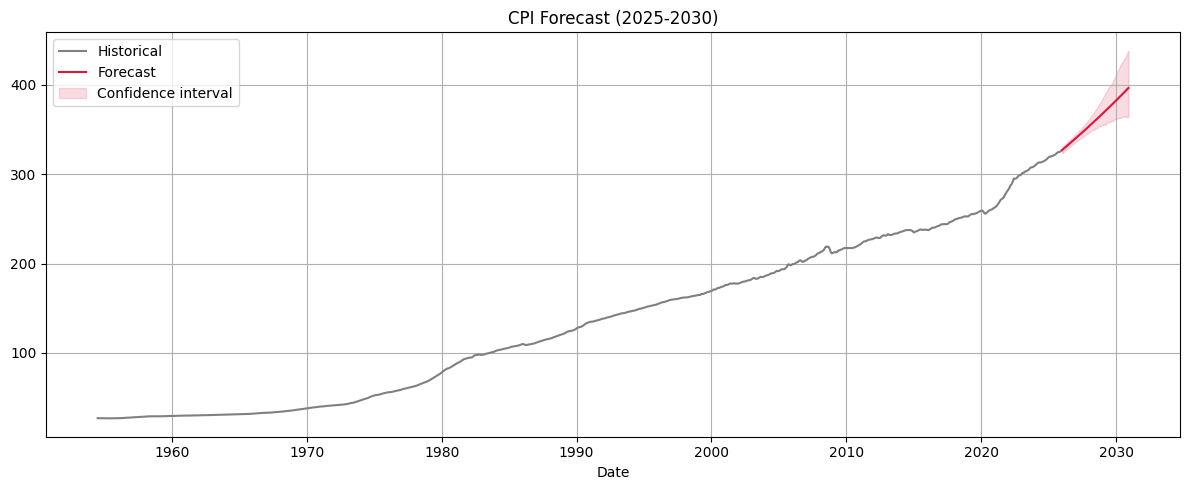

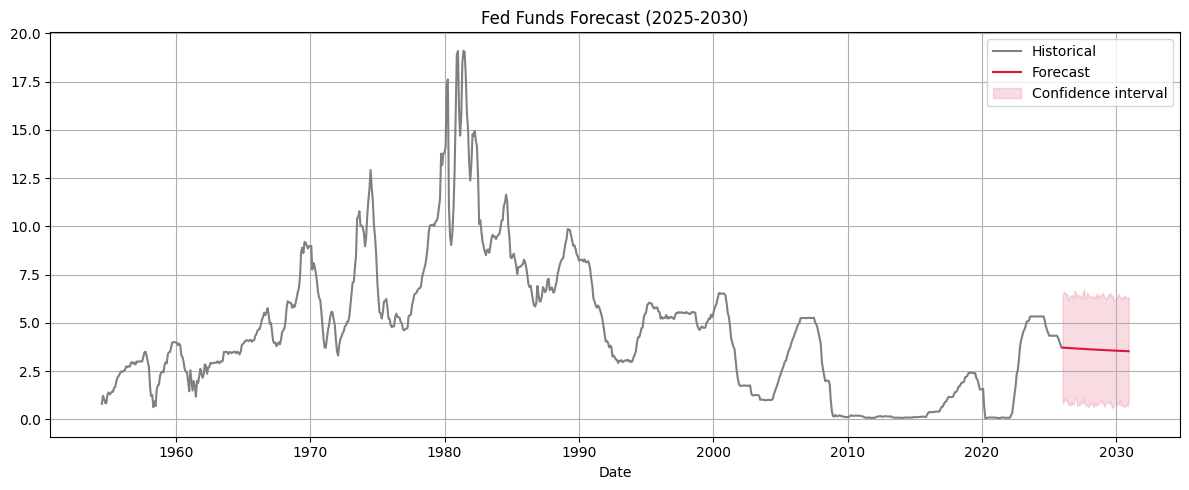

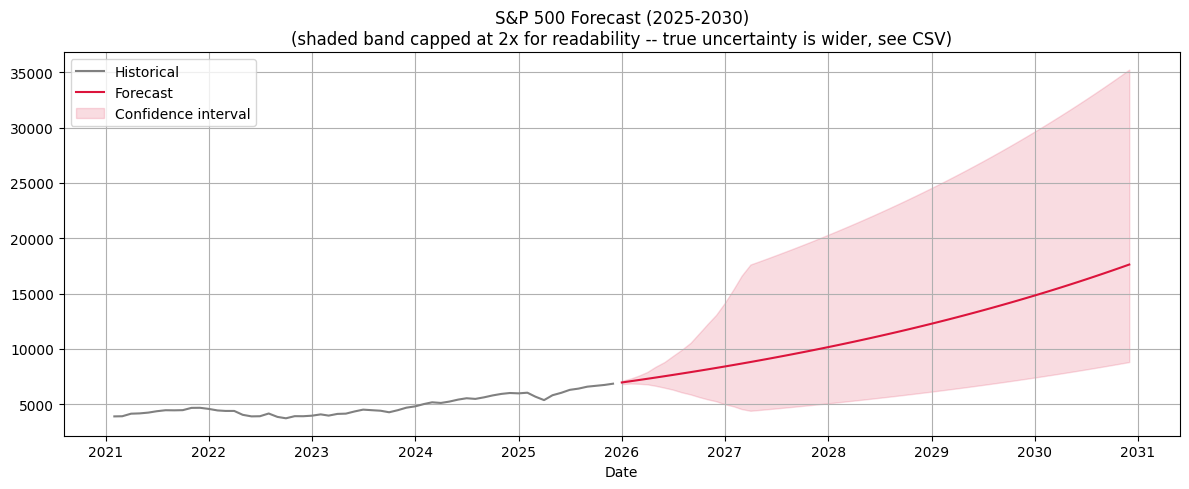

In [5]:
for name, fc_df, hist_df, title, clip_mult in [
    ("cpi_forecast.png", cpi_future, cpi_data, "CPI Forecast (2025-2030)", None),
    ("fedfunds_forecast.png", ff_future, ff_data, "Fed Funds Forecast (2025-2030)", None),
    ("sp500_forecast.png", sp_future, sp_data,
     "S&P 500 Forecast (2025-2030)\n(shaded band capped at 2x for readability -- true uncertainty is wider, see CSV)", 2.0),
]:
    plt.figure(figsize=(12, 5))
    plt.plot(hist_df["ds"], hist_df["y"], label="Historical", color="gray")
    plt.plot(fc_df["ds"], fc_df["yhat"], label="Forecast", color="crimson")
    lo, hi = fc_df["yhat_lower"], fc_df["yhat_upper"]
    if clip_mult:
        lo = np.maximum(lo, fc_df["yhat"] / clip_mult)
        hi = np.minimum(hi, fc_df["yhat"] * clip_mult)
    plt.fill_between(fc_df["ds"], lo, hi, color="crimson", alpha=0.15, label="Confidence interval")
    plt.title(title); plt.xlabel("Date"); plt.legend(); plt.grid(True)
    plt.tight_layout()
    plt.savefig(VIS + name, dpi=150)
    plt.show()

## Limitations (read before trusting these numbers)

- **SP500 forecast is low-confidence.** Only ~5 years of training data exist (a FRED
  licensing limit, not our choice), so uncertainty compounds hugely over a 5-year
  horizon. Treat the point forecast as directional at best, and the confidence interval
  as close to meaningless beyond ~12-18 months out.
- **Fed Funds is fundamentally a bad fit for trend-extrapolation models.** It's a
  policy-driven, mean-reverting, cyclical rate — not a growing quantity. The bounded
  (logistic) model here avoids the worst failure mode (runaway extrapolation in the
  wrong direction), but a 5-year-ahead Fed Funds forecast from trend extrapolation alone
  should be read as "roughly flat to gently declining, wide uncertainty" rather than a
  precise number.
- **CPI's forecast is the most defensible** of the three: 70 years of training data,
  smooth continuation from the last actual value, and inflation trends do have real
  persistence over multi-year horizons. Still, it assumes no future shock on the scale
  of 2021-23 — which is, by definition, unknowable in advance.